**Лабораторная работа #3 часть 2**

**Изучение метрик классификации при решении задач бинарной классификации**

**Описание задания к работе.**

**Часть 1.**

Основываясь на модели полученной в первой части работы 3.1. дополнить блокнот следующими метриками:

- Precision
- Recall
- F1
- Отрисовать тепловую карту матрицы ошибок
- Отрисовать кривую PR
- Отрисовать кривую ROC

Сделать вывод о качестве полученной модели

**Часть 2.**

Решить задачу классификации того же датасета, используя модели опорных векторов и ближайших соседей. Для каждой модели вывести метрики аналогично части 1 и сделать вывод о наилучшей из 3 рассмотренных моделей.

Загрузка необходимых модулей метрики (пример):  
from sklearn.metrics import confusion_matrix, precision_recall_curve  
from sklearn.metrics import recall_score, precision_score, f1_score

Подробнее о поддерживаемых метриках: https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score

warnings.filterwarnings('ignore')

### Подготовка данных (датасет 2 из работы 3.1: versicolor и virginica)
(Беру датасет 2 (versicolor и virginica) потому что в нём не достигается идеальная точность 1.0, как в датасете 1 (setosa и versicolor) и все метрики были бы равны 1, что неинтересно с точки зрения анализа)

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target

df2 = df[df['target'].isin([1, 2])]

X = df2.drop('target', axis=1)
y = (df2['target'] == 2).astype(int)  # 0 - versicolor, 1 - virginica (положительный класс)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Часть 1. Логистическая регрессия

In [3]:
clf = LogisticRegression(random_state=0)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]  # вероятность положительного класса

In [4]:
print('Precision: %.4f' % precision_score(y_test, y_pred))
print('Recall: %.4f' % recall_score(y_test, y_pred))
print('F1: %.4f' % f1_score(y_test, y_pred))

Precision: 0.9231
Recall: 0.9231
F1: 0.9231


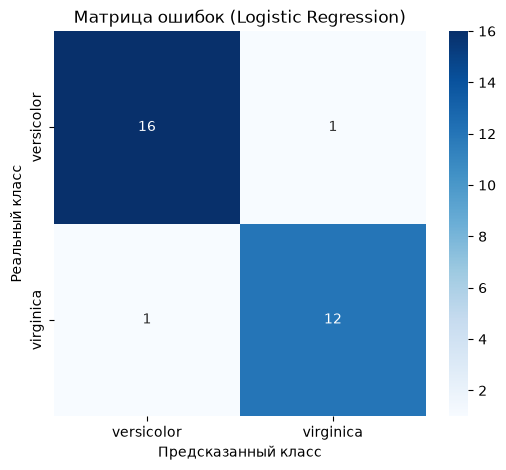

In [5]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['versicolor', 'virginica'], yticklabels=['versicolor', 'virginica'])
plt.xlabel('Предсказанный класс')
plt.ylabel('Реальный класс')
plt.title('Матрица ошибок (Logistic Regression)')
plt.show()

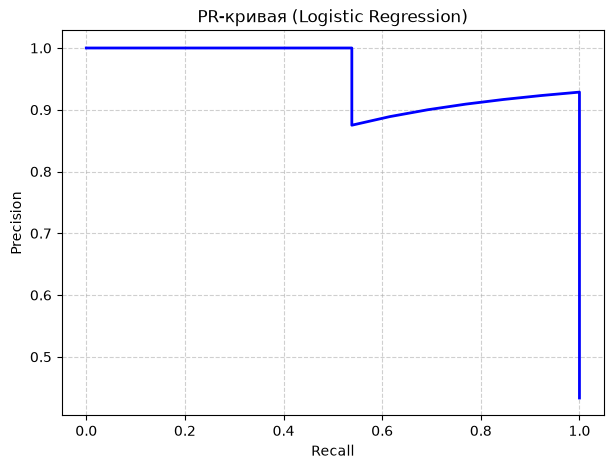

In [6]:
precision, recall, _ = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, color='blue', linewidth=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривая (Logistic Regression)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

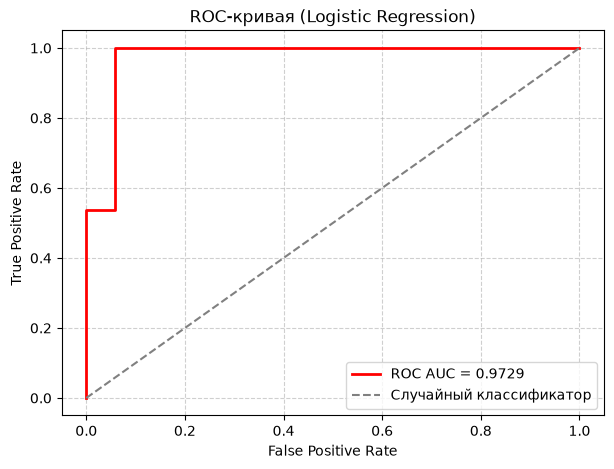

In [7]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='red', linewidth=2, label='ROC AUC = %.4f' % roc_auc)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Случайный классификатор')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая (Logistic Regression)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Вывод по части 1:** модель хорошо разделяет классы: Precision, Recall и F1 равны 0.9231, на 30 тестовых объектах допущено всего 2 ошибки (одна ложноположительная и одна ложноотрицательная), `ROC AUC` = 0.9729, кривая проходит близко к левому верхнему углу. Тестовая выборка маленькая, поэтому каждая ошибка заметно меняет метрики.

### Часть 2. Сравнение моделей: логистическая регрессия, SVM, KNN

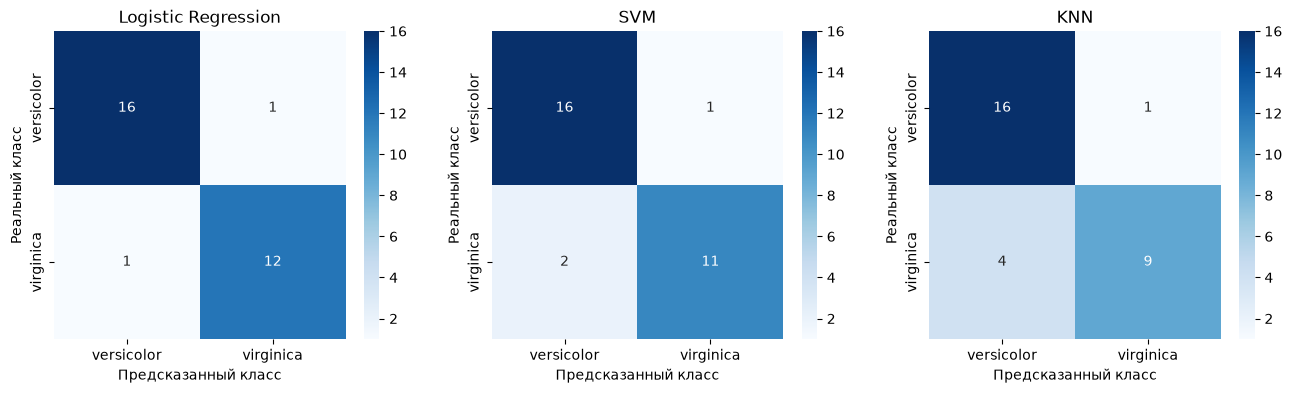

In [8]:
models = {
    'Logistic Regression': LogisticRegression(random_state=0),
    'SVM': SVC(probability=True, random_state=0),
    'KNN': KNeighborsClassifier()
}
colors = {'Logistic Regression': 'red', 'SVM': 'blue', 'KNN': 'green'}

metrics_list = []
curves = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['versicolor', 'virginica'], yticklabels=['versicolor', 'virginica'])
    ax.set_title(name)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Реальный класс')

    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    curves[name] = (precision, recall, fpr, tpr)

    metrics_list.append({
        'Модель': name,
        'Accuracy': round(model.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC AUC': round(auc(fpr, tpr), 4)
    })
plt.show()

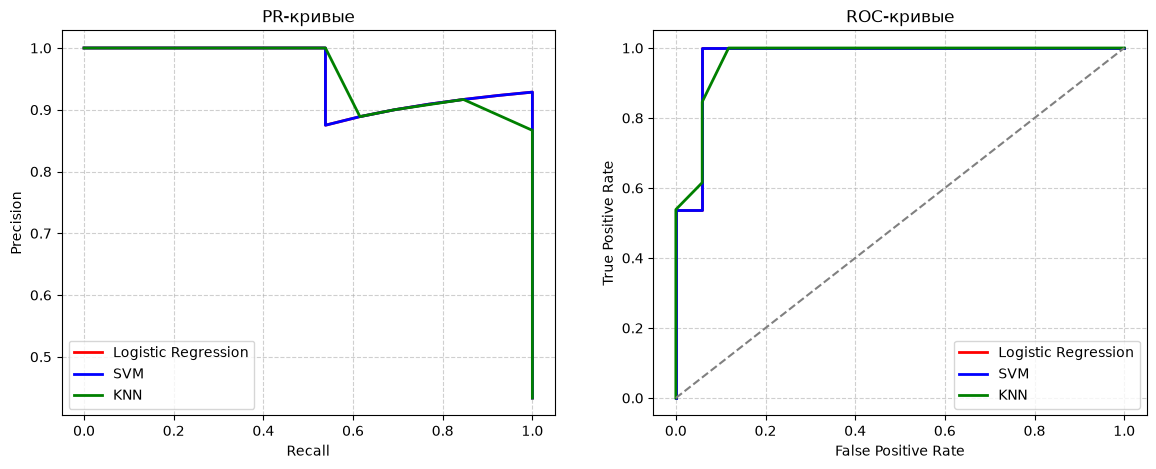

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, (precision, recall, fpr, tpr) in curves.items():
    axes[0].plot(recall, precision, color=colors[name], linewidth=2, label=name)
    axes[1].plot(fpr, tpr, color=colors[name], linewidth=2, label=name)

axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('PR-кривые')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)
plt.show()

(LR полностью совпала с SVM)

In [10]:
metrics_df = pd.DataFrame(metrics_list)
metrics_df

,Модель,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.9333,0.9231,0.9231,0.9231,0.9729
1,SVM,0.9000,0.9167,0.8462,0.8800,0.9729
2,KNN,0.8333,0.9000,0.6923,0.7826,0.9706


**Итог:** лучшей оказалась логистическая регрессия (F1 = 0.9231, Accuracy = 0.9333). SVM чуть хуже (F1 = 0.88), у KNN самый низкий Recall (0.6923) - он чаще пропускает virginica (F1 = 0.7826). По ROC AUC модели почти не отличаются (0.9729, 0.9729, 0.9706), то есть ранжируют объекты примерно одинаково, а разница возникает из-за порога классификации.